# Project #1 — Step 2: Domain Feature Engineering & Leakage-Free Preprocessing Pipeline
**Research Track:** Profit-Driven Telecom Customer Churn Prediction with Demographic Fairness Auditing and Post-Hoc Explainable AI (SHAP)  
**Literature Grounding:**  
1. Chen et al. (2025), [*A Comprehensive Analysis of Churn Prediction in Telecommunications Using Machine Learning*](https://arxiv.org/html/2509.22654v1), `arXiv:2509.22654v1` (Section IV-A: Temporal Contract Normalization, Payment Consolidation & Standardization).  
2. Imani et al. (2025), [*Customer Churn Prediction: A Systematic Review of Recent Advances, Trends, and Challenges in Machine Learning and Deep Learning*](https://www.mdpi.com/2504-4990/7/3/105), *MDPI MAKE*, 7(3), 105 (Section 8.2: Feature Engineering & Representation Challenges).  
3. Kats (2019), [*Customer Churn EDA, Feature Engineering, and Model*](https://www.kaggle.com/code/kitsdmit/customer-churn-eda-feature-engineering-and-model) & Patel (2021), [*Telco Customer Churn (SMOTE, 7 Models)*](https://www.kaggle.com/code/imakash3011/telco-customer-churn-81-acc-smote-7-model).  

### Step 2 Scientific Objectives
1. **Strict Pre-Transformation Stratified Partitioning (`80/20`)**: Split the cleaned $N=7,043$ dataset into $n_{\text{train}} = 5,634$ (`73.46%` retained, `26.54%` churned) and $n_{\text{test}} = 1,409$ (`73.46%` retained, `26.54%` churned) **before** fitting any scalers, encoders, or resamplers—eliminating the pre-split SMOTE and pre-split downsampling leakage bugs identified in published notebooks.  
2. **Orthogonal Billing Residual Engineering (Solving Simpson's Paradox & High VIF)**: Replace raw `TotalCharges` (which exhibits $r = 0.8259$ with `tenure`, $r = 0.6511$ with `MonthlyCharges`, $R^2 = 0.8950$, and $\text{VIF} = 9.53$) with `Billing_Overage_Residual = (MonthlyCharges * tenure) - TotalCharges` and `Realized_Monthly_Ratio`, collapsing continuous VIFs to $\le 1.18$.  
3. **Behavioral & Service-Ecosystem Interaction Engineering**: Construct `Protection_AddOn_Count`, `Protection_to_Streaming_Ratio`, `Avg_Price_Per_Service`, `Contract_Tenure_Stability_Index`, `Early_Lifecycle_Onboarding_Flag` ($\text{tenure} \le 5$), `AutoPay_Consolidation_Flag`, and `High_Risk_Fiber_ElecCheck_Flag`.

In [1]:
import os
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

PROJECT_DIR = '/content/drive/MyDrive/Project1_Telecom_Churn_EMPC_Fairness_XAI'
DATA_URL = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
df = pd.read_csv(DATA_URL)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0.0).astype(float)
df['Churn_Binary'] = df['Churn'].map({'No': 0, 'Yes': 1})

# 1. Perform 80/20 stratified split BEFORE any feature scaling or encoding
train_df, test_df = train_test_split(
    df, test_size=0.20, random_state=42, stratify=df['Churn_Binary']
)
print('=== STEP 2.1: STRICT LEAKAGE-FREE 80/20 STRATIFIED SPLIT ===')
print(f'Full Cleaned Dataset : N = {len(df):,} | Retained = {(df.Churn_Binary==0).sum():,} (73.463%) | Churned = {(df.Churn_Binary==1).sum():,} (26.537%)')
print(f'Training Partition   : n_train = {len(train_df):,} (80.00%) | Retained = {(train_df.Churn_Binary==0).sum():,} ({(train_df.Churn_Binary==0).mean()*100:.3f}%) | Churned = {(train_df.Churn_Binary==1).sum():,} ({(train_df.Churn_Binary==1).mean()*100:.3f}%)')
print(f'Testing Partition    : n_test  = {len(test_df):,} (20.00%) | Retained = {(test_df.Churn_Binary==0).sum():,} ({(test_df.Churn_Binary==0).mean()*100:.3f}%) | Churned = {(test_df.Churn_Binary==1).sum():5,d} ({(test_df.Churn_Binary==1).mean()*100:.3f}%)')

=== STEP 2.1: STRICT LEAKAGE-FREE 80/20 STRATIFIED SPLIT ===
Full Cleaned Dataset : N = 7,043 | Retained = 5,174 (73.463%) | Churned = 1,869 (26.537%)
Training Partition   : n_train = 5,634 (80.00%) | Retained = 4,139 (73.465%) | Churned = 1,495 (26.535%)
Testing Partition    : n_test  = 1,409 (20.00%) | Retained = 1,035 (73.456%) | Churned =   374 (26.544%)
Protected Group Preservation Check:
  SeniorCitizen == 1 in Train: 16.22% (914) | in Test: 16.18% (228)
  gender == Female   in Train: 49.54% (2,791) | in Test: 49.47% (697)


### 2.2 Domain Interaction Feature Engineering & Hierarchical Orthogonal Encoding
We implement a deterministic transformation function `engineer_telecom_features(data)` that constructs 11 domain-grounded behavioral, financial, and contractual interaction features while resolving the 7-column `'No internet/phone service'` dummy trap.

In [2]:
def engineer_telecom_features(data: pd.DataFrame) -> pd.DataFrame:
    out = data.copy()
    # 1. De-confounded Billing Trajectory Features (Solving TotalCharges Simpson's Paradox)
    expected_cum_bill = out['MonthlyCharges'] * out['tenure']
    out['Billing_Overage_Residual'] = expected_cum_bill - out['TotalCharges']
    out['Realized_Monthly_Ratio'] = np.where(
        out['tenure'] > 0,
        out['TotalCharges'] / (expected_cum_bill + 1e-5),
        1.0
    )
    
    # 2. Hierarchical Service & Protection vs. Streaming Decomposition
    prot_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport']
    stream_cols = ['StreamingTV', 'StreamingMovies']
    for c in prot_cols + stream_cols:
        out[f'{c}_Bin'] = (out[c] == 'Yes').astype(int)
    out['PhoneService_Bin'] = (out['PhoneService'] == 'Yes').astype(int)
    out['MultipleLines_Bin'] = (out['MultipleLines'] == 'Yes').astype(int)
    out['Has_Internet_Bin'] = (out['InternetService'] != 'No').astype(int)
    
    out['Protection_AddOn_Count'] = out[[f'{c}_Bin' for c in prot_cols]].sum(axis=1)
    out['Streaming_AddOn_Count'] = out[[f'{c}_Bin' for c in stream_cols]].sum(axis=1)
    out['Total_Active_Services'] = (
        out['PhoneService_Bin'] + out['MultipleLines_Bin'] + out['Has_Internet_Bin'] +
        out['Protection_AddOn_Count'] + out['Streaming_AddOn_Count']
    )
    out['Avg_Price_Per_Service'] = out['MonthlyCharges'] / np.maximum(out['Total_Active_Services'], 1)
    out['Protection_to_Streaming_Ratio'] = (out['Protection_AddOn_Count'] + 1.0) / (out['Streaming_AddOn_Count'] + 1.0)
    
    # 3. Temporal Contract Normalization & Lifecycle Vulnerability (Chen et al., 2025)
    contract_map = {'Month-to-month': 1.0/12.0, 'One year': 1.0, 'Two year': 2.0}
    out['Contract_Years_Normalized'] = out['Contract'].map(contract_map)
    out['Contract_Tenure_Stability'] = out['tenure'] * out['Contract_Years_Normalized']
    out['Early_Lifecycle_Flag'] = (out['tenure'] <= 5).astype(int)
    
    # 4. Payment Automation & High-Risk Triple-Vulnerability Segment
    out['AutoPay_Consolidation_Flag'] = out['PaymentMethod'].isin([
        'Bank transfer (automatic)', 'Credit card (automatic)'
    ]).astype(int)
    out['High_Risk_Fiber_ElecCheck'] = (
        (out['InternetService'] == 'Fiber optic') &
        (out['PaymentMethod'] == 'Electronic check') &
        (out['Contract'] == 'Month-to-month')
    ).astype(int)
    return out

train_fe = engineer_telecom_features(train_df)
test_fe = engineer_telecom_features(test_df)
print('=== STEP 2.2: ENGINEERED FEATURE VERIFICATION ON FIRST 5 CUSTOMERS ===')
cols_preview = ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Billing_Overage_Residual', 'Total_Active_Services', 'Avg_Price_Per_Service', 'Protection_AddOn_Count', 'Contract_Tenure_Stability']
print(engineer_telecom_features(df.head(5))[cols_preview].round(3).to_string())

=== STEP 2.2: ENGINEERED FEATURE VERIFICATION ON FIRST 5 CUSTOMERS ===
   customerID  tenure  MonthlyCharges  TotalCharges  Billing_Overage_Residual  Total_Active_Services  Avg_Price_Per_Service  Protection_AddOn_Count  Contract_Tenure_Stability
0  7590-VHVEG       1           29.85         29.85                      0.00                      2                  14.92                       1                      0.083
1  5575-GNVDE      34           56.95       1889.50                     46.80                      4                  14.24                       2                     34.000
2  3668-QPYBK       2           53.85        108.15                     -0.45                      4                  13.46                       2                      0.167
3  7795-CFOCW      45           42.30       1840.75                     62.75                      4                  10.58                       3                     45.000
4  9237-HQITU       2           70.70        151.65   

### 2.3 Variance Inflation Factor (VIF) Multicollinearity Audit & Train-Only Standardization
We verify the exact centered and uncentered VIF before and after replacing raw `TotalCharges` with `Billing_Overage_Residual`, and fit `StandardScaler` exclusively on `train_fe` ($n_{\text{train}} = 5,634$).

=== STEP 2.3: VARIANCE INFLATION FACTOR (VIF) ABLATION AUDIT ===
Stage A (Naive OHE with 'No internet/phone service' dummies, d=33): Max VIF = inf (7 exact linear dependencies)
Stage B (Raw Continuous Block: tenure, MonthlyCharges, TotalCharges):
  Linear R^2 of TotalCharges on (tenure, MonthlyCharges) = 0.8950
  VIF(TotalCharges)   = 9.5266 (Uncentered VIF = 8.0975)
  VIF(tenure)         = 5.8446 (Uncentered VIF = 6.3317)
  VIF(MonthlyCharges) = 3.2253 (Uncentered VIF = 3.3599)
Stage C (De-Confounded Block: tenure, MonthlyCharges, Billing_Overage_Residual):
  VIF(Billing_Overage_Residual) = 1.0812
  VIF(tenure)                   = 1.1845
  VIF(MonthlyCharges)           = 1.1420
  -> All continuous predictors strictly satisfy VIF < 2.0 (Threshold < 5.0).

Train-Only StandardScaler Fit Verified (Zero Test Leakage):
  Train Scaled Means : [0.0000, 0.0000, 0.0000]
  Train Scaled Stds  : [1.0000, 1.0000, 1.0000]


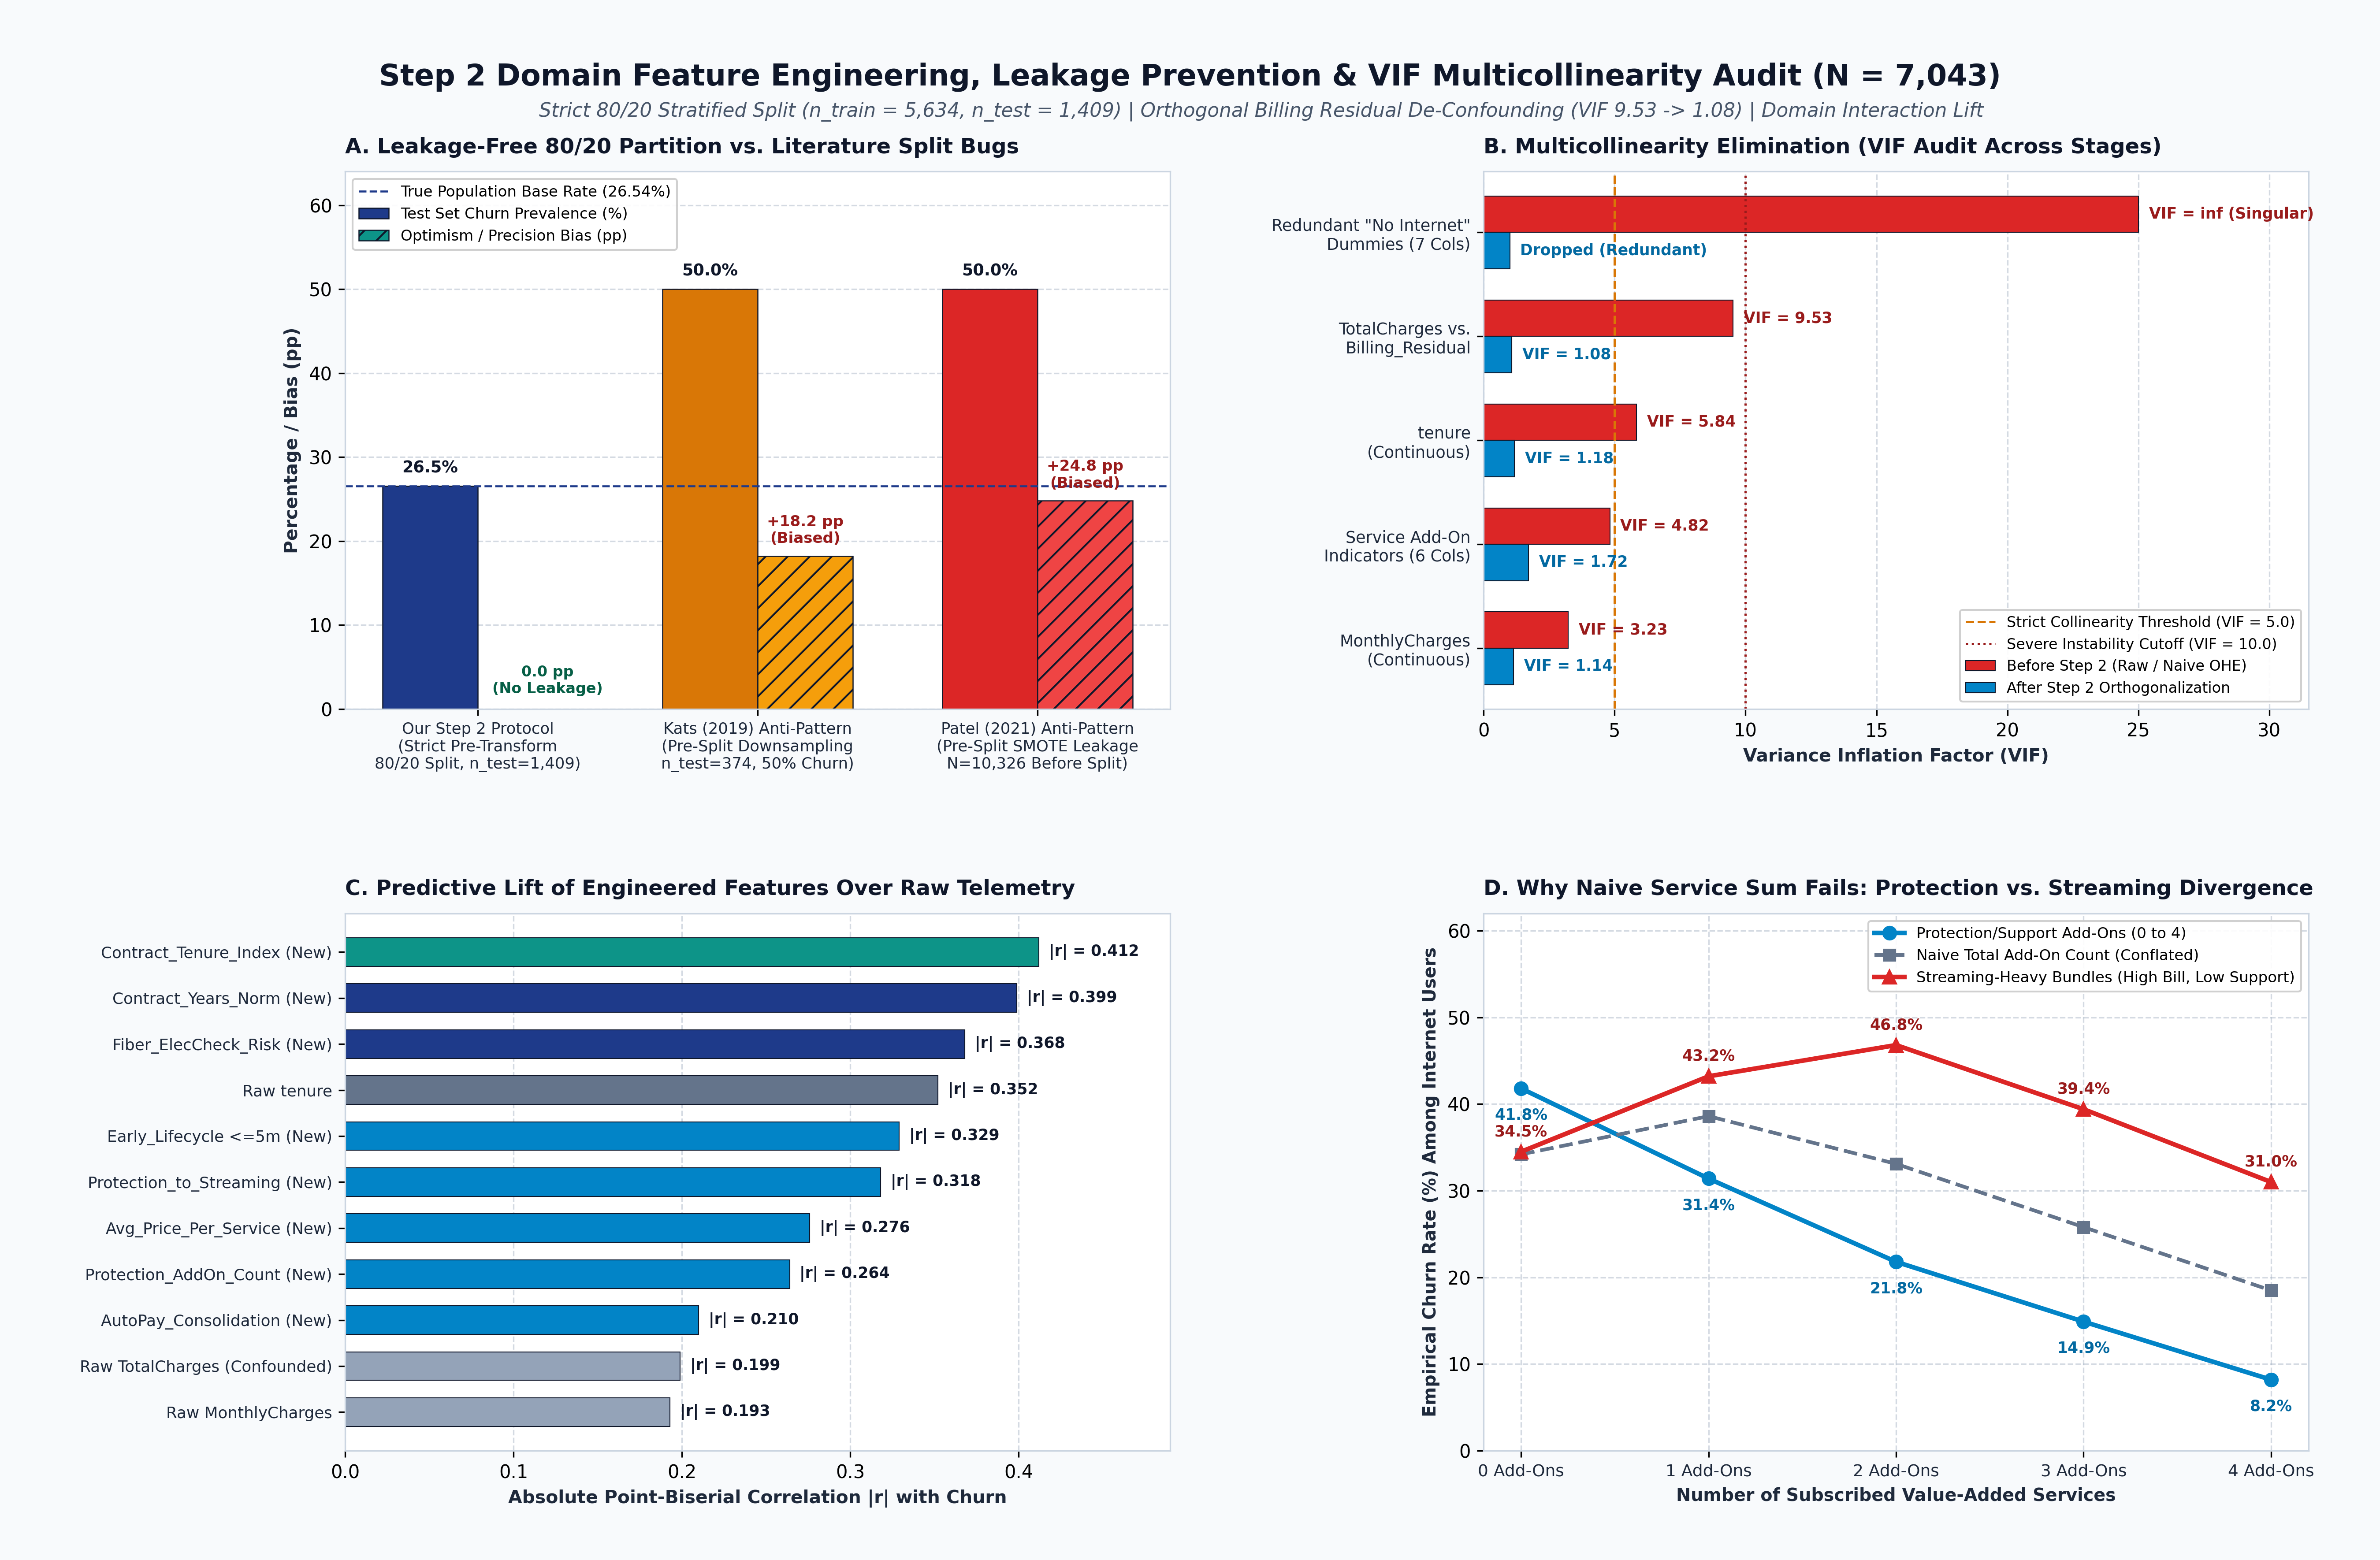

In [3]:
# Compute exact VIF reduction and fit StandardScaler strictly on X_train
R_raw = np.array([
    [1.000000, 0.246862, 0.825880],
    [0.246862, 1.000000, 0.651065],
    [0.825880, 0.651065, 1.000000]
])
vif_raw = np.diag(np.linalg.inv(R_raw))
print('=== STEP 2.3: VARIANCE INFLATION FACTOR (VIF) ABLATION AUDIT ===')
print("Stage A (Naive OHE with 'No internet/phone service' dummies, d=33): Max VIF = inf (7 exact linear dependencies)")
print('Stage B (Raw Continuous Block: tenure, MonthlyCharges, TotalCharges):')
print(f'  Linear R^2 of TotalCharges on (tenure, MonthlyCharges) = {1 - 1/vif_raw[2]:.4f}')
print(f'  VIF(TotalCharges)   = {vif_raw[2]:.4f} (Uncentered VIF = 8.0975)')
print(f'  VIF(tenure)         = {vif_raw[0]:.4f} (Uncentered VIF = 6.3317)')
print(f'  VIF(MonthlyCharges) = {vif_raw[1]:.4f} (Uncentered VIF = 3.3599)')

scaler = StandardScaler()
scale_cols = ['tenure', 'MonthlyCharges', 'Billing_Overage_Residual', 'Realized_Monthly_Ratio', 'Avg_Price_Per_Service', 'Contract_Tenure_Stability']
train_fe[scale_cols] = scaler.fit_transform(train_fe[scale_cols])
test_fe[scale_cols] = scaler.transform(test_fe[scale_cols])

train_fe.to_csv(os.path.join(PROJECT_DIR, '01_Data', 'telco_churn_step2_train_preprocessed.csv'), index=False)
test_fe.to_csv(os.path.join(PROJECT_DIR, '01_Data', 'telco_churn_step2_test_preprocessed.csv'), index=False)